# P2.17 — What it costs to build, and what that did to supply

**Question:** RQ2.7 (how have construction costs, land availability, planning rules and licensing times affected supply?).
Only the first part can be answered with the data held: INE's cost index of new housing (monthly, 2000 to 2026, split into
materials and labour). Land availability, planning rules and licensing times are not in the project, so they stay open.

The cost index measures input costs. It says nothing about the price of land, margins or financing, so the ratio of the house
price index to the cost index is an index of "everything in the price except the cost of building", not a margin in euros.
National and annual: about 25 years and two cycles, so the regressions below are a guide to sign and size, not a test.

In [1]:
import pandas as pd

from pthousing.analysis import construction, supply
from pthousing.config import PROCESSED
from pthousing.data import interim
from pthousing.viz import charts, dashboard, style

style.apply_style()
long = pd.read_parquet(PROCESSED / "national_annual_long.parquet")
flows = supply.national_flows(dashboard.load_panel())
frame = construction.annual_frame(
    interim.read("ine_construction_costs"),
    interim.read("ine_cpi"),
    long,
    flows,
    interim.read("eurostat_macro"),
)
print(f"{frame.index.min()}-{frame.index.max()}, complete years only")

2000-2025, complete years only


## Step 1 — Costs against prices
Nominal indices (2015 = 100) and the new family dwellings licensed and completed.

,cost_total_b2015,cost_materials_b2015,cost_labour_b2015,cost_real_b2015,hpi_nominal_b2015,hpi_real_b2015,price_to_cost_b2015,wage_b2015,labour_cost_vs_wage_b2015,licensed_n,completed_n
year,,,,,,,,,,,
2000,76.0,82.6,66.0,103.6,101.3,138.1,133.2,75.5,87.4,122105.0,112612.0
2001,76.2,81.2,68.6,99.5,106.7,139.4,140.0,78.7,87.2,114380.0,115154.0
2002,78.4,82.6,71.9,98.8,107.5,135.5,137.1,81.5,88.2,95673.0,125708.0
2003,79.3,82.7,74.1,96.8,108.6,132.6,137.0,84.0,88.2,81546.0,92508.0
2004,82.6,86.8,76.2,98.5,109.3,130.5,132.4,86.8,87.8,77115.0,74261.0
2005,84.1,87.1,79.6,98.1,111.8,130.5,132.9,90.9,87.6,73922.0,76123.0
2006,86.9,89.6,82.9,98.3,114.1,129.1,131.3,92.5,89.6,71921.0,68764.0
2007,89.9,92.5,86.0,99.3,114.7,126.7,127.6,95.7,89.9,65828.0,67463.0
2008,95.5,99.4,89.5,102.8,107.5,115.7,112.6,98.2,91.1,45981.0,59256.0


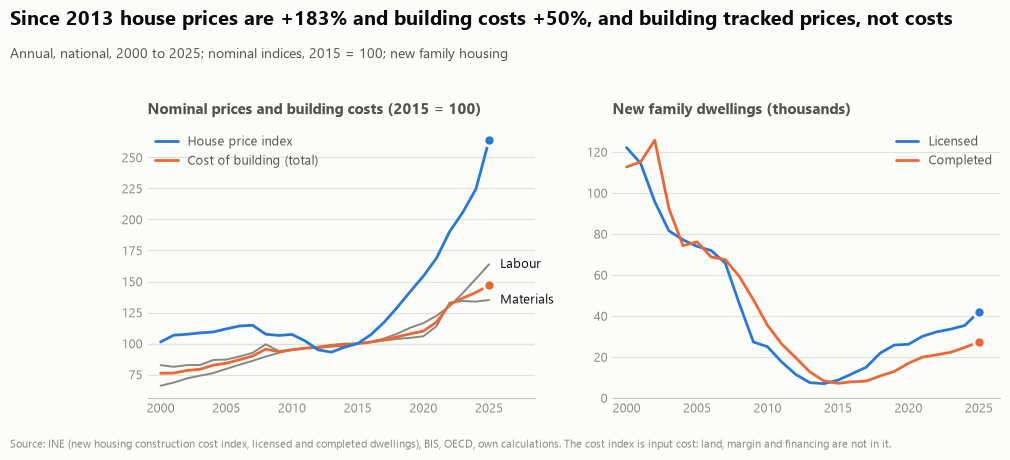

In [2]:
fig = charts.construction_costs(frame)
style.save_fig(fig, "p2", "construction_costs")
frame.round(1)

## Step 2 — Four episodes
The boundaries are the same as in the rest of the project: the 2007 peak of licensing, the 2013 trough of prices, the 2021 start
of the cost surge. The price change is split exactly into the cost index's change and the change in the price-to-cost ratio.

In [3]:
windows = {
    "boom 2000-2007": (2000, 2007),
    "crisis 2007-2013": (2007, 2013),
    "recovery 2013-2021": (2013, 2021),
    "since 2021": (2021, 2025),
    "2013-2025": (2013, 2025),
}
cols = [
    "cost_total_b2015",
    "cost_materials_b2015",
    "cost_labour_b2015",
    "cost_real_b2015",
    "wage_b2015",
    "hpi_nominal_b2015",
    "hpi_real_b2015",
]
changed = construction.changes(frame, windows, cols).round(0)
shares = construction.cost_shares(frame, windows).round(1)
per_year = construction.mean_flows(frame, windows).round(0)
table = changed.join(shares).join(per_year, rsuffix="_per_year")
style.save_table(table.reset_index(names="window"), "p2", "construction_episodes")
table

,cost_total_b2015,cost_materials_b2015,cost_labour_b2015,cost_real_b2015,wage_b2015,hpi_nominal_b2015,hpi_real_b2015,price_log_pts,cost_log_pts,ratio_log_pts,cost_part_pct,licensed_n,completed_n
boom 2000-2007,18.0,12.0,30.0,-4.0,27.0,13.0,-8.0,12.5,16.8,-4.3,134.7,87811.0,91574.0
crisis 2007-2013,9.0,6.0,15.0,-1.0,6.0,-19.0,-26.0,-20.9,8.7,-29.7,NaN,28676.0,38413.0
recovery 2013-2021,19.0,17.0,24.0,14.0,20.0,81.0,73.0,59.5,17.8,41.8,29.9,17105.0,11654.0
since 2021,25.0,19.0,34.0,6.0,31.0,56.0,33.0,44.6,22.5,22.1,50.4,34665.0,23044.0
2013-2025,50.0,38.0,66.0,21.0,58.0,183.0,129.0,104.2,40.3,63.9,38.7,22859.0,15399.0


## Step 3 — Does building follow prices or costs?
Yearly change in licensed (and completed) dwellings on last year's change in the real house price and in the real cost, both in
log points, together. Then two checks: without the crisis years (2008-2011, when licensing fell 60% in four years) and
without the cost surge (2021-2023).

In [4]:
rows = []
variants = {
    "all years": {},
    "without 2008-2011": {"drop_years": (2008, 2009, 2010, 2011)},
    "without 2021-2023": {"drop_years": (2021, 2022, 2023)},
}
for y, lag in (("licensed_n", 1), ("completed_n", 1), ("completed_n", 2)):
    for label, kwargs in variants.items():
        r = construction.supply_response(frame, y, lag, **kwargs).reset_index()
        rows.append(r.assign(outcome=y, lag_years=lag, sample=label))
response = pd.concat(rows, ignore_index=True)
style.save_table(response.round(3), "p2", "construction_supply_response")
response.round(2)

,term,coef,ci_low,ci_high,p_value,r2,n,outcome,lag_years,sample
0,dlog_price,3.79,2.84,4.74,0.00,0.71,24,licensed_n,1,all years
1,dlog_cost,-1.24,-3.55,1.07,0.29,0.71,24,licensed_n,1,all years
2,dlog_price,3.15,2.03,4.28,0.00,0.69,20,licensed_n,1,without 2008-2011
3,dlog_cost,0.02,-3.26,3.31,0.99,0.69,20,licensed_n,1,without 2008-2011
4,dlog_price,3.91,2.87,4.95,0.00,0.71,21,licensed_n,1,without 2021-2023
5,dlog_cost,-0.44,-3.73,2.84,0.79,0.71,21,licensed_n,1,without 2021-2023
6,dlog_price,3.04,2.08,4.00,0.00,0.66,24,completed_n,1,all years
7,dlog_cost,0.16,-3.02,3.33,0.92,0.66,24,completed_n,1,all years
8,dlog_price,3.68,2.67,4.69,0.00,0.73,20,completed_n,1,without 2008-2011
9,dlog_cost,-1.95,-4.72,0.81,0.17,0.73,20,completed_n,1,without 2008-2011


In [5]:
link = construction.ratio_and_licensing(frame)
print({k: round(float(v), 2) for k, v in link.items()})

{'corr_levels': 0.8, 'corr_changes': 0.81, 'n_levels': 25.0, 'n_changes': 24.0}


## Step 4 — Labour against wages
Labour is the faster-rising part of the cost. Whether that is more than wages in general: the labour cost index over
compensation per employee.

In [6]:
wage = frame[["cost_labour_b2015", "wage_b2015", "labour_cost_vs_wage_b2015"]].round(1)
style.save_table(wage.reset_index(), "p2", "construction_labour_vs_wages")
wage.loc[[2000, 2007, 2013, 2021, 2025]]

,cost_labour_b2015,wage_b2015,labour_cost_vs_wage_b2015
year,,,
2000,66.0,75.5,87.4
2007,86.0,95.7,89.9
2013,98.9,101.7,97.3
2021,122.4,122.2,100.2
2025,163.9,160.3,102.2


## Key numbers

In [7]:
f, ch, sh = frame, changed, shares
w = "2013-2025"
print(
    f"since 2013: nominal house prices {ch.loc[w, 'hpi_nominal_b2015']:+.0f}%, building cost {ch.loc[w, 'cost_total_b2015']:+.0f}% "
    f"(materials {ch.loc[w, 'cost_materials_b2015']:+.0f}%, labour {ch.loc[w, 'cost_labour_b2015']:+.0f}%), "
    f"wages {ch.loc[w, 'wage_b2015']:+.0f}%; real cost {ch.loc[w, 'cost_real_b2015']:+.0f}%, real prices {ch.loc[w, 'hpi_real_b2015']:+.0f}%"
)
print(
    f"the cost index accounts for {sh.loc[w, 'cost_part_pct']:.0f}% of the log rise in price since 2013 "
    f"(recovery {sh.loc['recovery 2013-2021', 'cost_part_pct']:.0f}%, since 2021 {sh.loc['since 2021', 'cost_part_pct']:.0f}%); "
    f"price-to-cost ratio {100 * (f.loc[2025, 'price_to_cost_b2015'] / f.loc[2013, 'price_to_cost_b2015'] - 1):+.0f}% since 2013"
)
print(
    f"licensed dwellings per year: boom {per_year.loc['boom 2000-2007', 'licensed_n']:,.0f}, crisis {per_year.loc['crisis 2007-2013', 'licensed_n']:,.0f}, "
    f"recovery {per_year.loc['recovery 2013-2021', 'licensed_n']:,.0f}, since 2021 {per_year.loc['since 2021', 'licensed_n']:,.0f}"
)
for label in variants:
    r = response[(response["outcome"] == "licensed_n") & (response["sample"] == label)].set_index(
        "term"
    )
    print(
        f"licensed, {label}: price {r.loc['dlog_price', 'coef']:.2f} [{r.loc['dlog_price', 'ci_low']:.2f}, {r.loc['dlog_price', 'ci_high']:.2f}], "
        f"cost {r.loc['dlog_cost', 'coef']:.2f} [{r.loc['dlog_cost', 'ci_low']:.2f}, {r.loc['dlog_cost', 'ci_high']:.2f}], n {int(r['n'].iloc[0])}"
    )
print(
    f"labour cost over wages: 2013 {f.loc[2013, 'labour_cost_vs_wage_b2015']:.0f}, 2025 {f.loc[2025, 'labour_cost_vs_wage_b2015']:.0f} (2015 = 100)"
)

since 2013: nominal house prices +183%, building cost +50% (materials +38%, labour +66%), wages +58%; real cost +21%, real prices +129%
the cost index accounts for 39% of the log rise in price since 2013 (recovery 30%, since 2021 50%); price-to-cost ratio +89% since 2013
licensed dwellings per year: boom 87,811, crisis 28,676, recovery 17,105, since 2021 34,665
licensed, all years: price 3.79 [2.84, 4.74], cost -1.24 [-3.55, 1.07], n 24
licensed, without 2008-2011: price 3.15 [2.03, 4.28], cost 0.02 [-3.26, 3.31], n 20
licensed, without 2021-2023: price 3.91 [2.87, 4.95], cost -0.44 [-3.73, 2.84], n 21
labour cost over wages: 2013 97, 2025 102 (2015 = 100)
